# Week12 A — qbgf algorithm

Run All is safe by default: synthetic smoke or read-only metadata. Full work requires changing the FLAGS cell yourself. The agent has not enabled full runs. Completed checksummed rows resume automatically; a changed scientific identity fails instead of overwriting. QASPER TEST and all Week13 confirmation outcomes are blocked.

W12-C uses the full frozen VALIDATION split. The historical W11 pilot is hypothesis generation only. W12-I freezes the reviewed method; Week13 is the future locked evaluation. No outcome from reserved confirmation may inform selection.


In [1]:
CORE_FINAL = True
RUN_SMOKE = True
RUN_FULL = False
RESUME = True
OVERWRITE = False
SMOKE_LIMIT = 3
RUN_REAL_MODEL_SMOKE = True
RUN_CANONICAL_SMOKE = False
ALLOW_LLMLINGUA_DOWNLOAD = False
RUN_LLMLINGUA_SMOKE = True
RUN_LLMLINGUA_FULL = False
RUN_TINY_LORA_SMOKE = True
RUN_FULL_LORA_TRAIN = False
FINAL_METHOD = None
FINAL_REASON = None
RETAIN_LORA = False


In [2]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT=Path.cwd().resolve()
while not (ROOT/'src/week12').is_dir():
    if ROOT==ROOT.parent: raise FileNotFoundError('Open within CS787-RAG-Project')
    ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.week12.protocol import load, root
from src.week12.runner import execute
cfg=load()
if OVERWRITE or not RESUME: raise ValueError('Immutable results: RESUME=True, OVERWRITE=False required')
effective_smoke=RUN_SMOKE and not RUN_FULL
print('MODE:', 'MANUAL FULL DEVELOPMENT' if RUN_FULL else 'SMOKE ONLY' if effective_smoke else 'READ SAVED ONLY')


MODE: SMOKE ONLY


## Execute / resume

All necessary setup is derived above. CORE_FINAL=True restricts C/D to preregistered primary methods and budgets; secondary sensitivities require CORE_FINAL=False. No follow-on cell silently enables a full run.

W12-A prepared 1/3; completed selections are reused
W12-A prepared 2/3; completed selections are reused
W12-A prepared 3/3; completed selections are reused


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 5/5 [00:02<00:00,  1.90it/s]
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,HELP,HURT,NEUTRAL,all_gold_recall,answer_changed,answer_type,any_gold_recall,budget,budget_utilization,candidate_content_hashes,...,real_smoke,selected_unit_ids,selection_seconds,source_hash,source_support,split,synthetic,task_score,unmapped_gold,unused_budget
0,False,False,True,NaN,False,NOT_ENOUGH_INFO,NaN,256,0.972656,[278447bd0de181f9f188f997e7db1d6f6f93597f04fce...,...,True,"[e5445c1d81c48abff40db4f6b402da93, 0f59f9005a6...",0.030256,43ab6502d167753f49c2e2a513b32bb69529692272af1a...,1.0,VALIDATION,False,0.000000,0,7
1,False,False,True,1.0,True,comparison,1.0,256,0.968750,[9bb96f347e426c239391600ac2ca54624339a9499e045...,...,True,"[66898ff81a644d1cbf1fa8fc97d8df68, edbb2e2c700...",0.018604,71fcf97f4b13318fb85bf14f2eb33a9f34c4a52ef6c93c...,1.0,VALIDATION,False,0.000000,0,8
2,True,False,False,0.0,True,extractive,0.0,256,0.996094,[026bcdc3296aef5777fced8f68d0aee2e2c60c404e0df...,...,True,"[de9d79bdcbbad9ca9ea597188b391a84, 7d2bc1b5bf4...",0.036523,361829010ee4e2a958ebae6862eb620f41a5c84f9de9fc...,1.0,VALIDATION,False,0.461538,0,1


SYNTHETIC rows are pipeline checks, never findings. Completed real rows are reused by identity.


,passage_id,text,score
0,2372c19ffc2eebbfb9b68d6d3ee40900,An experiment observed a red signal. The appen...,0.492366


,sentence_id,passage_id,start,end,text,score
0,04f4ef41277877d81a3de399eac69f2a,2372c19ffc2eebbfb9b68d6d3ee40900,0,36,An experiment observed a red signal.,0.666667
1,32e439c2050bca840176228dbe88a3a9,2372c19ffc2eebbfb9b68d6d3ee40900,37,71,The appendix discusses blue paint.,0.000000


,name,cost,utility,actual_k,mass,passage_id,passage_weight,selection_rank_ids
0,DROP,0,0.000000,0.0,0.000000,2372c19ffc2eebbfb9b68d6d3ee40900,1.0,NaN
1,SENT_1,7,0.965555,1.0,0.965555,2372c19ffc2eebbfb9b68d6d3ee40900,1.0,[04f4ef41277877d81a3de399eac69f2a]
2,SENT_2,13,1.000000,2.0,1.000000,2372c19ffc2eebbfb9b68d6d3ee40900,1.0,"[04f4ef41277877d81a3de399eac69f2a, 32e439c2050..."
3,FULL,13,1.000000,NaN,1.000000,2372c19ffc2eebbfb9b68d6d3ee40900,1.0,NaN


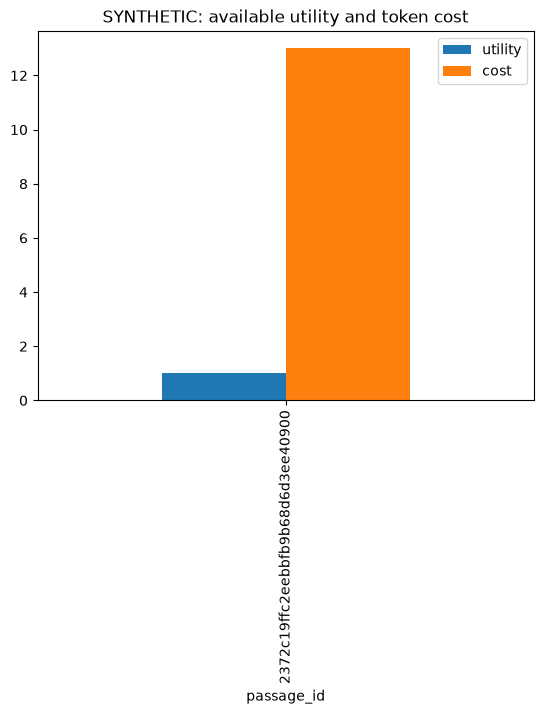

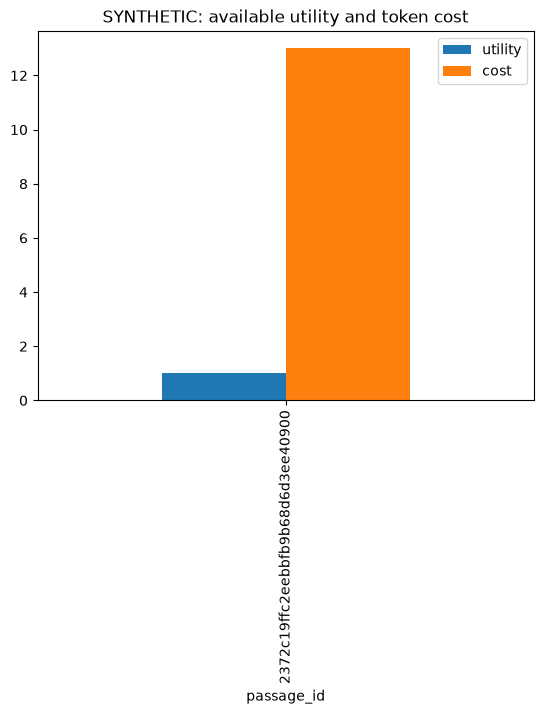

In [3]:
result=execute('A',cfg,full=RUN_FULL,smoke=effective_smoke,explicit=RUN_FULL,limit=SMOKE_LIMIT,real_smoke=RUN_REAL_MODEL_SMOKE,core_final=CORE_FINAL)
display(pd.DataFrame(result))
print('SYNTHETIC rows are pipeline checks, never findings. Completed real rows are reused by identity.')
from src.week12.runner import fixture_examples
from src.week12.laboratory import Lab
from src.week12.algorithm import options
from src.week11.budgets import FixtureTokenizer
example=fixture_examples()[0]
lab=Lab(cfg,FixtureTokenizer(),synthetic=True)
try:
    pool,sent,props,ps,ss,lineage=lab.prepare(example)
    display(pd.DataFrame([{'passage_id':p['unit_id'],'text':p['source_text'],'score':score} for p,score in zip(pool,ps)]))
    display(pd.DataFrame([{'sentence_id':s['unit_id'],'passage_id':s['passage_id'],'start':s['start_char'],'end':s['end_char'],'text':s['source_text'],'score':ss[s['unit_id']]} for s in sent]))
    table=pd.DataFrame([{k:v for k,v in o.items() if k not in ('units','ids')} for group in options(pool,sent,ps,ss,FixtureTokenizer()) for o in group])
    display(table)
    display(table.groupby('passage_id')[['utility','cost']].max().plot.bar(title='SYNTHETIC: available utility and token cost').figure)
finally: lab.close()


## Interpretation and next step

Use the method registry and primary comparison table. No automatic winner promotion. Compare QBGF with RAW_SKIP and fixed sentences; relevance mass is a surrogate, not predicted F1. Macro-F1 is recomputed per resample. QASPER/Mistral specialists are separate from Qwen comparisons. All confirmation data remain locked.